# Лабораторная работа №3
## «Понижение размерности»

**Дисциплина:** Введение в интеллектуальный анализ данных  
**Датасет:** Wine Recognition (`wine_dataset.csv`, 178 объектов, 13 числовых физико-химических признаков + сорт вина)

**Цель работы:**
1. Изучить проблему высокой размерности данных и её влияние на анализ.
2. Освоить методы линейного (PCA) и нелинейного (t-SNE, UMAP) снижения размерности.
3. Научиться выявлять скрытую структуру данных и интерпретировать результаты преобразований.
4. Научиться интерпретировать новые признаки (главные компоненты) и оценивать качество сжатия данных.

In [2]:
# При необходимости установите umap-learn:
# !pip install umap-learn

import os
import numpy as np
import pandas as pd
import scipy.optimize
from scipy.spatial.distance import cdist
from scipy.sparse.csgraph import laplacian
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import mean_squared_error

try:
    import umap
    HAS_UMAP = True
except ImportError:
    HAS_UMAP = False
    print("Библиотека umap-learn не установлена — будет использована встроенная реализация алгоритма UMAP на NumPy/SciPy.")

# Настройка визуализации
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

# Загрузка датасета (из локального CSV с резервной загрузкой из sklearn)
if os.path.exists("wine_dataset.csv"):
    df = pd.read_csv("wine_dataset.csv")
else:
    wine = load_wine(as_frame=True)
    df = wine.frame.rename(columns={
        'alcohol': 'Alcohol', 'malic_acid': 'Malic_Acid', 'ash': 'Ash',
        'alcalinity_of_ash': 'Alcalinity_of_Ash', 'magnesium': 'Magnesium',
        'total_phenols': 'Total_Phenols', 'flavanoids': 'Flavanoids',
        'nonflavanoid_phenols': 'Nonflavanoid_Phenols', 'proanthocyanins': 'Proanthocyanins',
        'color_intensity': 'Color_Intensity', 'hue': 'Hue',
        'od280/od315_of_diluted_wines': 'OD280_OD315', 'proline': 'Proline',
        'target': 'Cultivar'
    })
    df['Cultivar_Name'] = df['Cultivar'].map({
        0: 'Сорт 1 (Barolo)', 1: 'Сорт 2 (Grignolino)', 2: 'Сорт 3 (Barbera)'
    })

PALETTE = {
    'Сорт 1 (Barolo)': '#1F4E79',
    'Сорт 2 (Grignolino)': '#E07A5F',
    'Сорт 3 (Barbera)': '#2E8B57'
}
HUE_ORDER = ['Сорт 1 (Barolo)', 'Сорт 2 (Grignolino)', 'Сорт 3 (Barbera)']

print(f"Датасет успешно загружен: {df.shape[0]} строк, {df.shape[1]} столбцов")
df.head()

Библиотека umap-learn не установлена — будет использована встроенная реализация алгоритма UMAP на NumPy/SciPy.
Датасет успешно загружен: 178 строк, 15 столбцов


,Alcohol,Malic_Acid,Ash,Alcalinity_of_Ash,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280_OD315,Proline,Cultivar,Cultivar_Name
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,Сорт 1 (Barolo)
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,Сорт 1 (Barolo)
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,Сорт 1 (Barolo)
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,Сорт 1 (Barolo)
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,Сорт 1 (Barolo)


## Задание 1. Геометрия данных в пространстве признаков

Одна строка датасета — это **один образец итальянского вина** из региона Пьемонт, относящийся к одному из трёх сортов винограда (`Barolo`, `Grignolino`, `Barbera`), описанный результатами химического анализа.

**Выбранные числовые признаки (13 признаков, целевая метка сорта `Cultivar` используется только для раскраски графиков):**
1. `Alcohol` — содержание алкоголя (%).
2. `Malic_Acid` — концентрация яблочной кислоты (г/л).
3. `Ash` — зольность (г/л).
4. `Alcalinity_of_Ash` — щёлочность золы.
5. `Magnesium` — содержание магния (мг/л).
6. `Total_Phenols` — общее содержание фенолов.
7. `Flavanoids` — содержание флавоноидов.
8. `Nonflavanoid_Phenols` — содержание нефлавоноидных фенолов.
9. `Proanthocyanins` — содержание проантоцианинов.
10. `Color_Intensity` — интенсивность цвета.
11. `Hue` — оттенок цвета.
12. `OD280_OD315` — оптическая плотность разбавленных вин ($OD_{280}/OD_{315}$).
13. `Proline` — содержание аминокислоты пролина (мг/л).

In [3]:
features = [
    'Alcohol', 'Malic_Acid', 'Ash', 'Alcalinity_of_Ash', 'Magnesium',
    'Total_Phenols', 'Flavanoids', 'Nonflavanoid_Phenols', 'Proanthocyanins',
    'Color_Intensity', 'Hue', 'OD280_OD315', 'Proline'
]
X_df = df[features].copy()
X_raw = X_df.values
y = df['Cultivar'].values
y_names = df['Cultivar_Name'].values

print("=== ИНФОРМАЦИЯ О ДАТАСЕТЕ ===")
print(f"Число объектов:  {X_df.shape[0]}")
print(f"Число признаков: {X_df.shape[1]}")
print("\nРаспределение по сортам вина:")
print(df['Cultivar_Name'].value_counts())

print("\n=== ОПИСАТЕЛЬНАЯ СТАТИСТИКА ===")
display(X_df.describe().T.round(3))

print("\n=== ПРОВЕРКА ПРОПУСКОВ ===")
print(f"Всего пропущенных значений: {X_df.isna().sum().sum()}")

=== ИНФОРМАЦИЯ О ДАТАСЕТЕ ===
Число объектов:  178
Число признаков: 13

Распределение по сортам вина:
Cultivar_Name
Сорт 2 (Grignolino)    71
Сорт 1 (Barolo)        59
Сорт 3 (Barbera)       48
Name: count, dtype: int64

=== ОПИСАТЕЛЬНАЯ СТАТИСТИКА ===


,count,mean,std,min,25%,50%,75%,max
Alcohol,178.0,13.001,0.812,11.03,12.362,13.050,13.678,14.83
Malic_Acid,178.0,2.336,1.117,0.74,1.602,1.865,3.082,5.80
Ash,178.0,2.367,0.274,1.36,2.210,2.360,2.558,3.23
Alcalinity_of_Ash,178.0,19.495,3.340,10.60,17.200,19.500,21.500,30.00
Magnesium,178.0,99.742,14.282,70.00,88.000,98.000,107.000,162.00
Total_Phenols,178.0,2.295,0.626,0.98,1.742,2.355,2.800,3.88
Flavanoids,178.0,2.029,0.999,0.34,1.205,2.135,2.875,5.08
Nonflavanoid_Phenols,178.0,0.362,0.124,0.13,0.270,0.340,0.438,0.66
Proanthocyanins,178.0,1.591,0.572,0.41,1.250,1.555,1.950,3.58
Color_Intensity,178.0,5.058,2.318,1.28,3.220,4.690,6.200,13.00



=== ПРОВЕРКА ПРОПУСКОВ ===
Всего пропущенных значений: 0


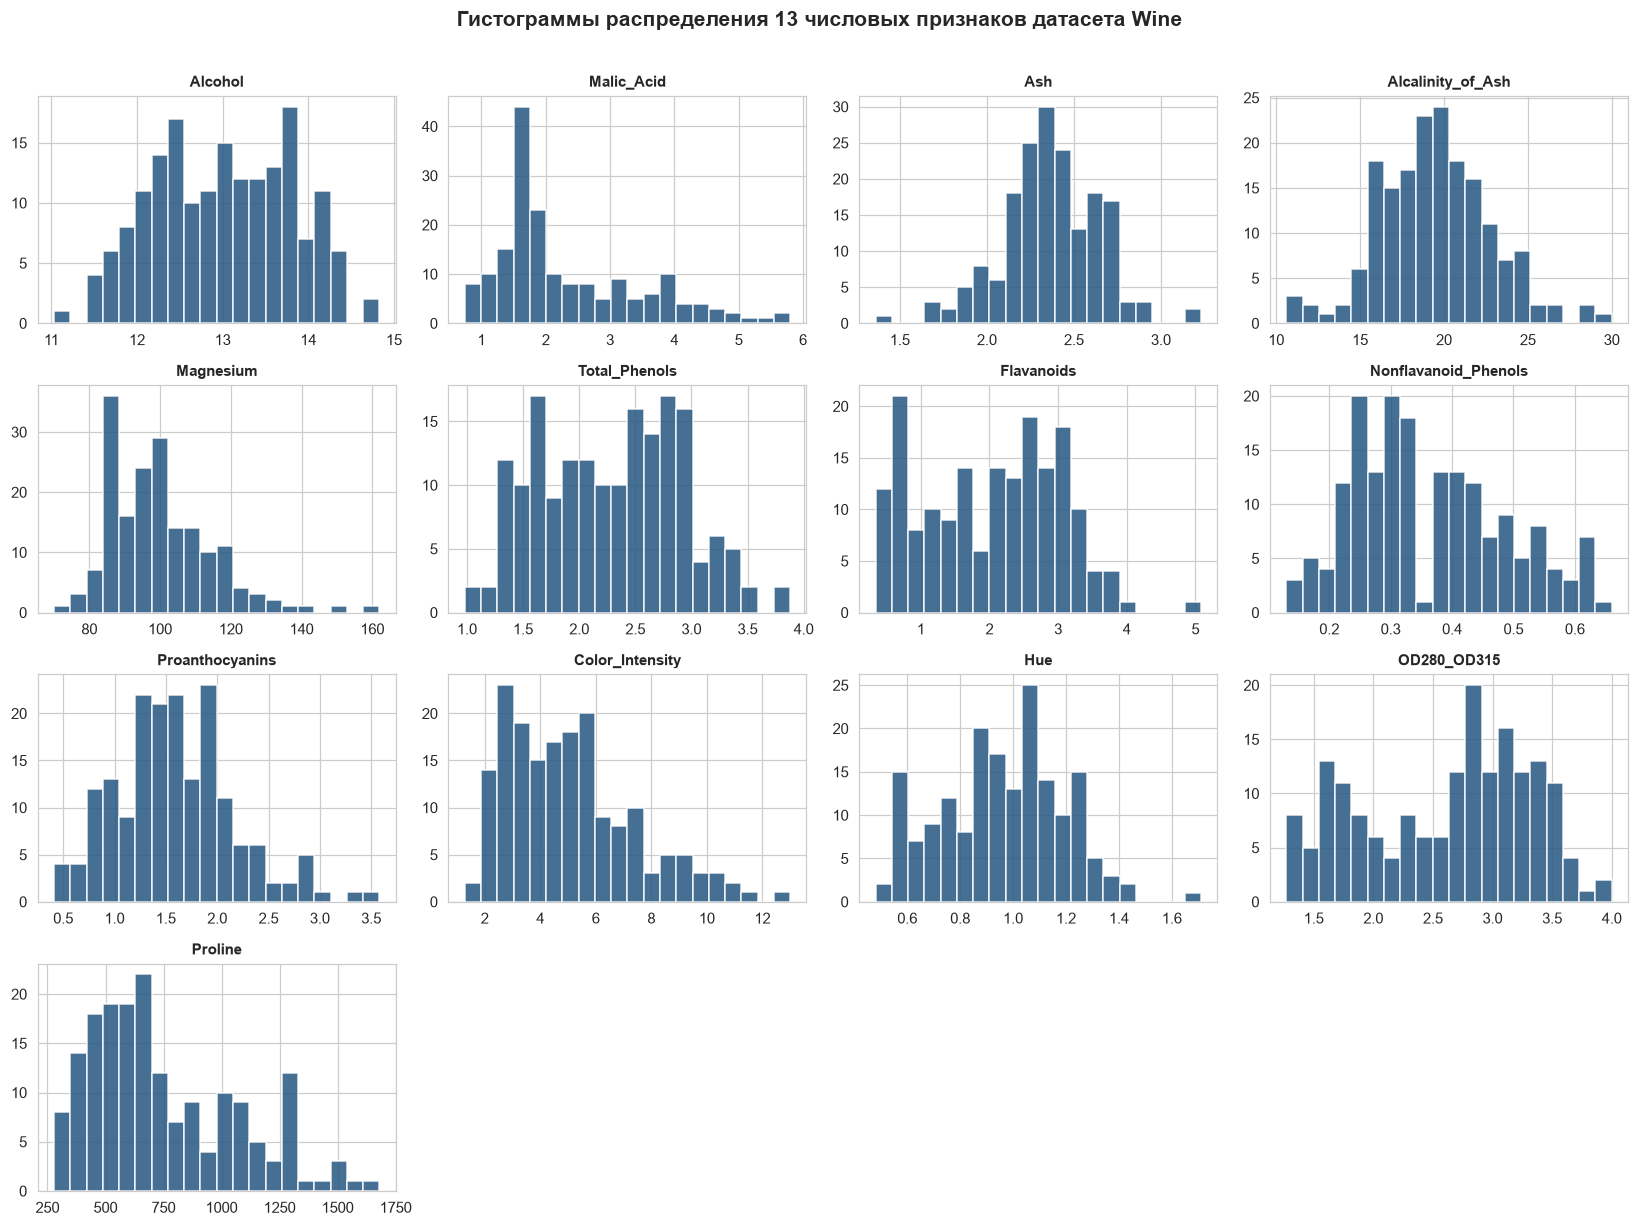

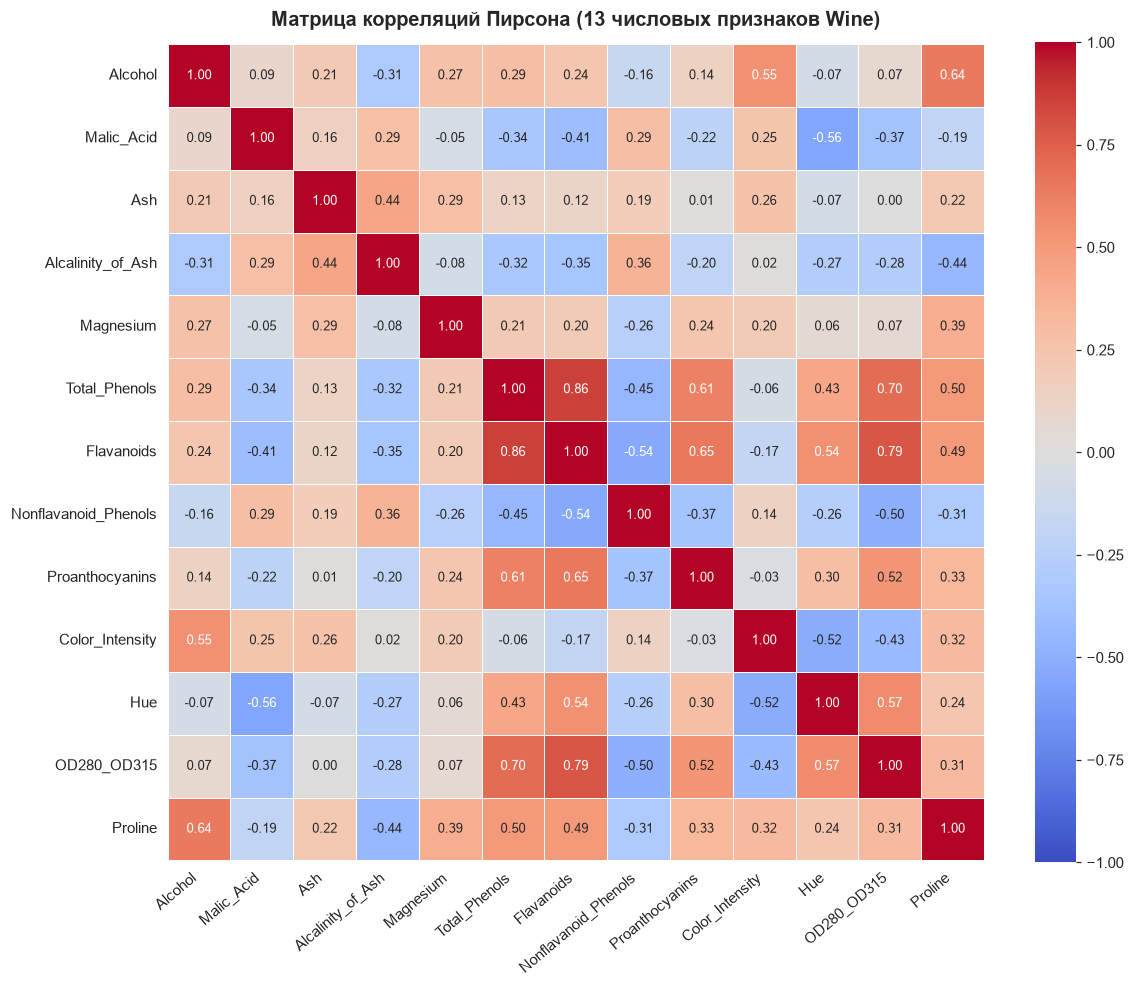

In [4]:
# 1.2 Гистограммы распределения признаков
fig, axes = plt.subplots(4, 4, figsize=(15, 11))
axes = axes.flatten()
for i, col in enumerate(features):
    axes[i].hist(X_df[col], bins=20, edgecolor='white', color='#2B5B84', alpha=0.88)
    axes[i].set_title(col, fontsize=10, fontweight='bold')
for j in range(len(features), len(axes)):
    axes[j].axis('off')
fig.suptitle("Гистограммы распределения 13 числовых признаков датасета Wine", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Матрица корреляций признаков
corr_matrix = X_df.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, annot_kws={"size": 8.5}, square=True)
plt.title("Матрица корреляций Пирсона (13 числовых признаков Wine)", fontsize=13, fontweight='bold', pad=12)
plt.xticks(rotation=40, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Ответы на вопросы Задания 1

| Вопрос | Ответ по датасету `wine_dataset.csv` |
| :--- | :--- |
| **Есть ли сильно коррелированные признаки?** | **Да.** Самая сильная положительная связь наблюдается между `Total_Phenols` и `Flavanoids` ($r = 0.86$), а также между `Flavanoids` и `OD280_OD315` ($r = 0.79$), `Total_Phenols` и `OD280_OD315` ($r = 0.70$), `Flavanoids` и `Proanthocyanins` ($r = 0.65$), `Alcohol` и `Proline` ($r = 0.64$). Заметная отрицательная корреляция есть между `Malic_Acid` и `Hue` ($r = -0.56$), `Flavanoids` и `Nonflavanoid_Phenols` ($r = -0.54$). |
| **Можно ли предположить, что часть признаков содержит избыточную информацию?** | **Да.** Химическая группа фенольных соединений (`Total_Phenols`, `Flavanoids`, `Proanthocyanins`, `OD280_OD315`, `Nonflavanoid_Phenols`) дублирует описание одного и того же физико-химического свойства — насыщенности вина полифенолами. Кроме того, масштабы признаков различаются на порядки (`Proline` достигает $1680$, тогда как `Nonflavanoid_Phenols` лежит в диапазоне $0.13\dots 0.66$), что делает обязательной стандартизацию перед PCA. |

## Задание 2. Реализация PCA с нуля (только NumPy)

Алгоритм включает 5 обязательных шагов:
1. **Стандартизация данных:**
$$X_{\text{std}} = \frac{X - \mu}{\sigma}$$
2. **Вычисление ковариационной матрицы:**
$$\Sigma = \frac{1}{n - 1} X_{\text{std}}^T X_{\text{std}}$$
3. **Нахождение собственных значений и собственных векторов** симметричной матрицы $\Sigma$ (`np.linalg.eigh`).
4. **Сортировка компонент** по убыванию собственных значений ($\lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_d$).
5. **Проекция данных** на первые $k$ главных компонент:
$$Z = X_{\text{std}} W_k$$

In [5]:
class CustomPCA:
    def __init__(self, n_components=None):
        self.n_components = n_components
        self.mean_ = None
        self.scale_ = None
        self.components_ = None
        self.explained_variance_ = None
        self.explained_variance_ratio_ = None

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        # 1. Стандартизация данных
        self.mean_ = np.mean(X, axis=0)
        self.scale_ = np.std(X, axis=0, ddof=0)
        X_std = (X - self.mean_) / self.scale_

        # 2. Вычисление ковариационной матрицы
        n_samples = X_std.shape[0]
        cov_matrix = np.dot(X_std.T, X_std) / (n_samples - 1)

        # 3. Нахождение собственных значений и собственных векторов
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

        # 4. Сортировка компонент по убыванию собственных значений
        sorted_idx = np.argsort(eigenvalues)[::-1]
        eigenvalues = eigenvalues[sorted_idx]
        eigenvectors = eigenvectors[:, sorted_idx]

        self.explained_variance_ = eigenvalues
        self.explained_variance_ratio_ = eigenvalues / np.sum(eigenvalues)

        k = self.n_components if self.n_components is not None else X.shape[1]
        self.components_ = eigenvectors[:, :k].T
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        X_std = (X - self.mean_) / self.scale_
        # 5. Проекция данных на первые k компонент
        return np.dot(X_std, self.components_.T)

    def fit_transform(self, X):
        return self.fit(X).transform(X)

    def inverse_transform(self, Z):
        # Обратное преобразование из пространства главных компонент в исходный масштаб признаков
        return np.dot(Z, self.components_) * self.scale_ + self.mean_

# Сравнение с sklearn.decomposition.PCA
custom_pca_2 = CustomPCA(n_components=2)
Z_custom = custom_pca_2.fit_transform(X_raw)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
sk_pca_2 = PCA(n_components=2)
Z_sk = sk_pca_2.fit_transform(X_scaled)

print("=== СРАВНЕНИЕ CUSTOM PCA (NUMPY) И SKLEARN.DECOMPOSITION.PCA ===")
print("Доля дисперсии (Custom PCA): ", np.round(custom_pca_2.explained_variance_ratio_[:2], 6))
print("Доля дисперсии (Sklearn PCA):", np.round(sk_pca_2.explained_variance_ratio_, 6))
print(f"Макс. расхождение долей дисперсии: {np.max(np.abs(custom_pca_2.explained_variance_ratio_[:2] - sk_pca_2.explained_variance_ratio_)):.2e}")
print(f"Макс. расхождение координат (с точностью до знака оси): {np.max(np.abs(np.abs(Z_custom) - np.abs(Z_sk))):.2e}")

=== СРАВНЕНИЕ CUSTOM PCA (NUMPY) И SKLEARN.DECOMPOSITION.PCA ===
Доля дисперсии (Custom PCA):  [0.361988 0.192075]
Доля дисперсии (Sklearn PCA): [0.361988 0.192075]
Макс. расхождение долей дисперсии: 0.00e+00
Макс. расхождение координат (с точностью до знака оси): 8.88e-16


Компонент для объяснения >= 80% дисперсии: 5 (накоплено 80.16%)
Компонент для объяснения >= 95% дисперсии: 10 (накоплено 96.17%)


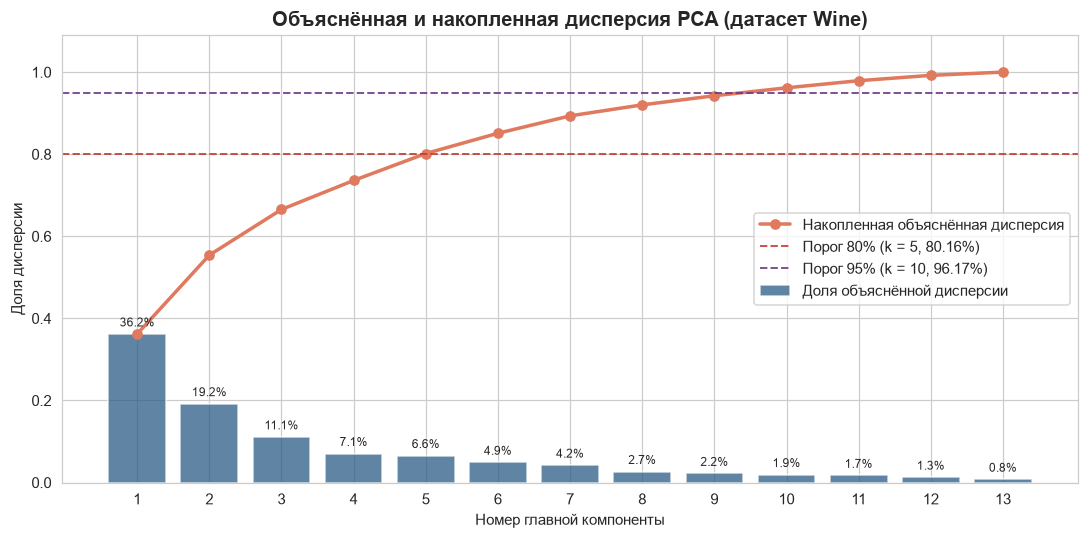

In [6]:
# 2.1 Исследование объяснённой дисперсии
full_pca = CustomPCA().fit(X_raw)

# Фиксируем однозначную ориентацию осей PC1, PC2 и PC3 по ведущим признакам,
# чтобы знаки нагрузок и ориентация графиков не зависели от версии библиотек
anchor_features = ['Flavanoids', 'Color_Intensity', 'Ash']
for idx, feat in enumerate(anchor_features):
    feat_idx = features.index(feat)
    if full_pca.components_[idx, feat_idx] < 0:
        full_pca.components_[idx] *= -1

evr = full_pca.explained_variance_ratio_
cum_evr = np.cumsum(evr)

n_80 = int(np.argmax(cum_evr >= 0.80) + 1)
n_95 = int(np.argmax(cum_evr >= 0.95) + 1)

print(f"Компонент для объяснения >= 80% дисперсии: {n_80} (накоплено {cum_evr[n_80-1]*100:.2f}%)")
print(f"Компонент для объяснения >= 95% дисперсии: {n_95} (накоплено {cum_evr[n_95-1]*100:.2f}%)")

fig, ax = plt.subplots(figsize=(10, 5))
x_ticks = np.arange(1, len(evr) + 1)
ax.bar(x_ticks, evr, alpha=0.75, label="Доля объяснённой дисперсии", color="#2B5B84", edgecolor="white")
ax.plot(x_ticks, cum_evr, marker="o", color="#E07A5F", linewidth=2.3, label="Накопленная объяснённая дисперсия")
ax.axhline(0.80, color="#C0392B", linestyle="--", linewidth=1.3, alpha=0.85, label=f"Порог 80% (k = {n_80}, {cum_evr[n_80-1]*100:.2f}%)")
ax.axhline(0.95, color="#6C3483", linestyle="--", linewidth=1.3, alpha=0.85, label=f"Порог 95% (k = {n_95}, {cum_evr[n_95-1]*100:.2f}%)")
for i, v in enumerate(evr):
    ax.text(x_ticks[i], v + 0.012, f"{v*100:.1f}%", ha='center', va='bottom', fontsize=8)
ax.set_xticks(x_ticks)
ax.set_ylim(0, 1.09)
ax.set_xlabel("Номер главной компоненты")
ax.set_ylabel("Доля дисперсии")
ax.set_title("Объяснённая и накопленная дисперсия PCA (датасет Wine)", fontsize=13, fontweight='bold')
ax.legend(loc='center right', frameon=True)
plt.tight_layout()
plt.show()

### Ответы на вопросы Задания 2.1

* **Сравнение с `sklearn.decomposition.PCA`:** Результаты собственной реализации на NumPy совпали с `scikit-learn` с точностью до машинной погрешности ($\sim 10^{-15}$).
* **Сколько компонент объясняют 80% дисперсии?** **5 главных компонент** (накопленная дисперсия составляет **80.16%**).
* **Сколько компонент объясняют 95% дисперсии?** **10 главных компонент** (накопленная дисперсия составляет **96.17%**).

## Задание 3. Интерпретация главных компонент

Рассмотрим коэффициенты (нагрузки, *loadings*) исходных 13 признаков в первых трёх главных компонентах `PC1`, `PC2` и `PC3`.

=== КОЭФФИЦИЕНТЫ ПРИЗНАКОВ В ПЕРВЫХ ТРЁХ КОМПОНЕНТАХ ===


,PC1,PC2,PC3
Alcohol,0.1443,0.4837,-0.2074
Malic_Acid,-0.2452,0.2249,0.0890
Ash,-0.0021,0.3161,0.6262
Alcalinity_of_Ash,-0.2393,-0.0106,0.6121
Magnesium,0.1420,0.2996,0.1308
Total_Phenols,0.3947,0.0650,0.1462
Flavanoids,0.4229,-0.0034,0.1507
Nonflavanoid_Phenols,-0.2985,0.0288,0.1704
Proanthocyanins,0.3134,0.0393,0.1495
Color_Intensity,-0.0886,0.5300,-0.1373


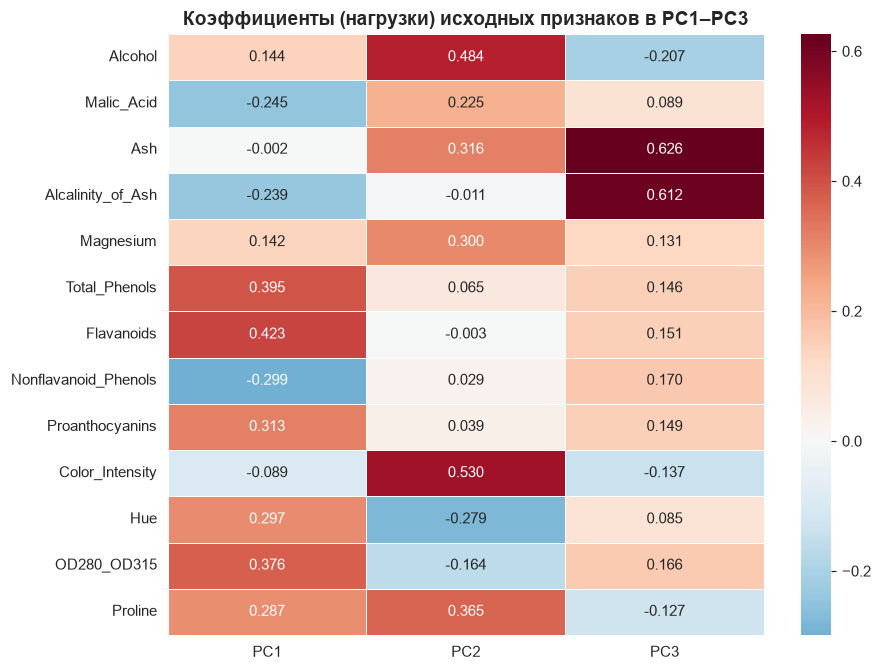

Наибольший вклад в PC1: Flavanoids (+0.423), Total_Phenols (+0.395), OD280_OD315 (+0.376), Proanthocyanins (+0.313)
Наибольший вклад в PC2: Color_Intensity (+0.530), Alcohol (+0.484), Proline (+0.365), Ash (+0.316)
Наибольший вклад в PC3: Ash (+0.626), Alcalinity_of_Ash (+0.612), Alcohol (-0.207), Nonflavanoid_Phenols (+0.170)


In [7]:
loadings = pd.DataFrame(
    full_pca.components_[:3].T,
    columns=["PC1", "PC2", "PC3"],
    index=features
)

print("=== КОЭФФИЦИЕНТЫ ПРИЗНАКОВ В ПЕРВЫХ ТРЁХ КОМПОНЕНТАХ ===")
display(loadings.round(4))

plt.figure(figsize=(8.5, 6.2))
sns.heatmap(loadings, annot=True, fmt=".3f", cmap="RdBu_r", center=0, linewidths=0.5)
plt.title("Коэффициенты (нагрузки) исходных признаков в PC1–PC3", fontsize=12.5, fontweight='bold')
plt.tight_layout()
plt.show()

for pc in ["PC1", "PC2", "PC3"]:
    top_f = loadings[pc].abs().sort_values(ascending=False).head(4)
    formatted = [f"{name} ({loadings.loc[name, pc]:+.3f})" for name in top_f.index]
    print(f"Наибольший вклад в {pc}: {', '.join(formatted)}")

### Ответы на вопросы Задания 3

| Компонента | Доля дисперсии | Признаки с наибольшим вкладом | Содержательная интерпретация | Слабо влияющие признаки |
| :--- | :---: | :--- | :--- | :--- |
| **PC1** | **36.20%** | `Flavanoids` (+0.423), `Total_Phenols` (+0.395), `OD280_OD315` (+0.376), `Proanthocyanins` (+0.313), `Nonflavanoid_Phenols` (-0.299), `Hue` (+0.297) | **Фенольный и антиоксидантный профиль вина** (противопоставляет богатые флавоноидами вина образцам с высокой долей нефлавоноидных фенолов и яблочной кислоты) | `Ash` (-0.002), `Color_Intensity` (-0.089) |
| **PC2** | **19.21%** | `Color_Intensity` (+0.530), `Alcohol` (+0.484), `Proline` (+0.365), `Ash` (+0.316), `Magnesium` (+0.300) | **Крепость, интенсивность цвета и экстрактивность вина** (отделяет насыщенные высокоалкогольные вина от лёгких светлых вин с высоким `Hue` -0.279) | `Flavanoids` (-0.003), `Alcalinity_of_Ash` (-0.011), `Nonflavanoid_Phenols` (+0.029) |
| **PC3** | **11.12%** | `Ash` (+0.626), `Alcalinity_of_Ash` (+0.612) | **Минеральный состав и щёлочность золы** | `Hue` (+0.085), `Malic_Acid` (+0.089) |

1. **Какие признаки больше всего влияют на PC1?** Прежде всего группа фенольных соединений и оптической плотности: `Flavanoids` (+0.423), `Total_Phenols` (+0.395), `OD280_OD315` (+0.376), `Proanthocyanins` (+0.313), а с обратным знаком — `Nonflavanoid_Phenols` (-0.299).
2. **Можно ли интерпретировать PC1 как комбинацию исходных признаков?** **Да.** PC1 представляет собой взвешенную линейную комбинацию, которая физически описывает **интегральный «фенольно-антиоксидантный индекс» вина**, объясняющий более трети всей изменчивости датасета.
3. **Есть ли признаки, которые практически не влияют на первые компоненты?** **Да.** Признак `Ash` (зольность) имеет нагрузку всего **-0.002** в `PC1` (практически нулевое влияние), раскрываясь лишь в `PC3` (+0.626). В `PC2` практически не участвуют `Flavanoids` (-0.003) и `Alcalinity_of_Ash` (-0.011).

## Задание 4. Визуализация данных (до и после PCA)

Сравним двумерное отображение образцов по двум исходным признакам (`Alcohol` и `Malic_Acid`) и по двум первым главным компонентам (`PC1` и `PC2`), раскрасив точки по сорту вина.

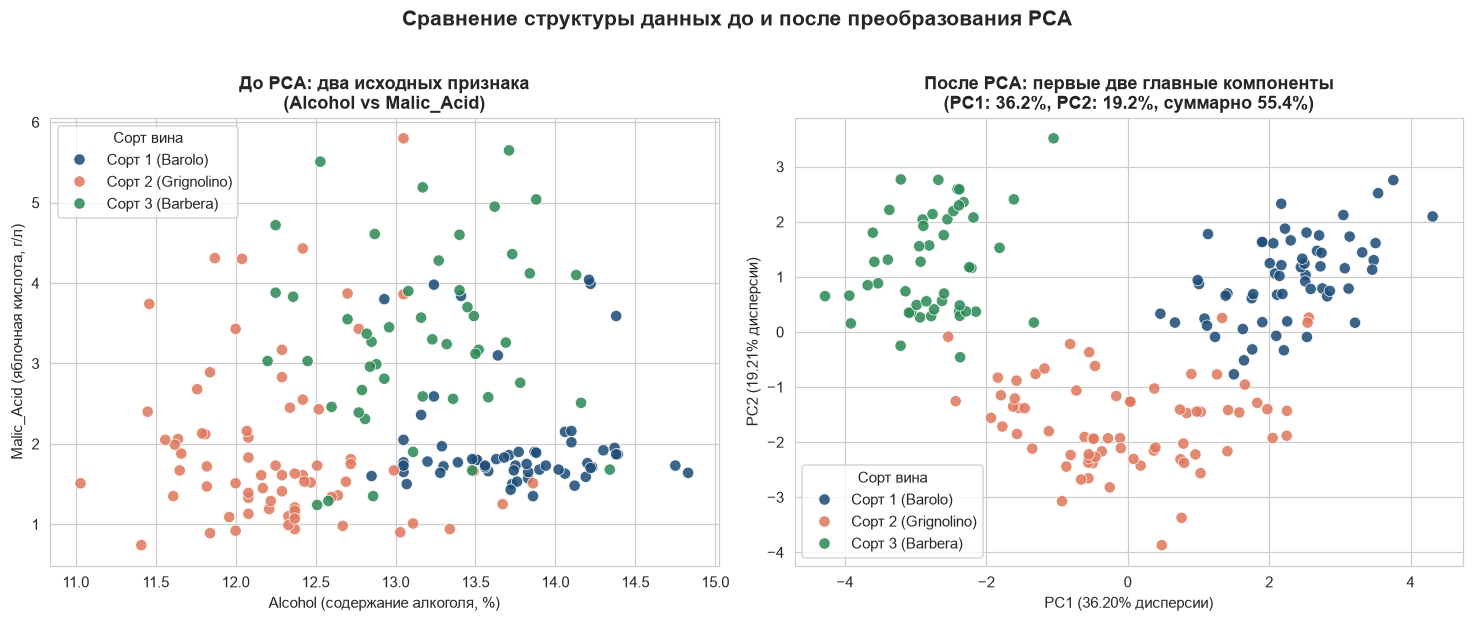

In [8]:
Z_full = full_pca.transform(X_raw)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5))

sns.scatterplot(x=X_df['Alcohol'], y=X_df['Malic_Acid'], hue=y_names, hue_order=HUE_ORDER,
                palette=PALETTE, s=55, alpha=0.88, edgecolor='white', linewidth=0.5, ax=axes[0])
axes[0].set_title("До PCA: два исходных признака\n(Alcohol vs Malic_Acid)", fontsize=11.5, fontweight='bold')
axes[0].set_xlabel("Alcohol (содержание алкоголя, %)")
axes[0].set_ylabel("Malic_Acid (яблочная кислота, г/л)")
axes[0].legend(title="Сорт вина")

sns.scatterplot(x=Z_full[:, 0], y=Z_full[:, 1], hue=y_names, hue_order=HUE_ORDER,
                palette=PALETTE, s=55, alpha=0.88, edgecolor='white', linewidth=0.5, ax=axes[1])
axes[1].set_title(f"После PCA: первые две главные компоненты\n(PC1: {evr[0]*100:.1f}%, PC2: {evr[1]*100:.1f}%, суммарно {(evr[0]+evr[1])*100:.1f}%)",
                  fontsize=11.5, fontweight='bold')
axes[1].set_xlabel(f"PC1 ({evr[0]*100:.2f}% дисперсии)")
axes[1].set_ylabel(f"PC2 ({evr[1]*100:.2f}% дисперсии)")
axes[1].legend(title="Сорт вина")

plt.suptitle("Сравнение структуры данных до и после преобразования PCA", fontsize=13.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Ответы на вопросы Задания 4

1. **Улучшилась ли визуализация после PCA?** **Да, кардинально.** В исходных координатах `Alcohol` и `Malic_Acid` три сорта вин заметно перекрываются (особенно `Barbera` с `Barolo` и `Grignolino`), так как два отдельно взятых параметра не передают всей химической специфики. На плоскости `PC1–PC2` все три сорта формируют **три чётко различимых компактных кластера**:
   * **Сорт 1 (Barolo)** расположен в правой верхней области (высокий фенольный индекс + высокая крепость и насыщенность цвета).
   * **Сорт 2 (Grignolino)** занимает нижнюю центральную часть (более лёгкие и менее интенсивные по цвету вина).
   * **Сорт 3 (Barbera)** отделён в левой верхней области (низкий фенольный индекс, высокая кислотность и насыщенный цвет).
2. **Почему в пространстве главных компонент структура может быть заметнее?** Первые две компоненты `PC1` и `PC2` аккумулируют **55.41%** суммарной дисперсии сразу всех 13 признаков. Вместо произвольного «среза» по двум столбцам PCA поворачивает пространство вдоль направлений максимального разброса данных, объединяя коррелированные признаки и отсекая второстепенный шум.

## Задание 5. Нелинейные методы снижения размерности: t-SNE и UMAP

Исследуем работу нелинейных алгоритмов **t-SNE** (при `perplexity = 5, 30, 50`) и **UMAP** (при изменении `n_neighbors = 5, 15, 50` и `min_dist = 0.1, 0.5`), а затем сопоставим их напрямую с линейным методом PCA.

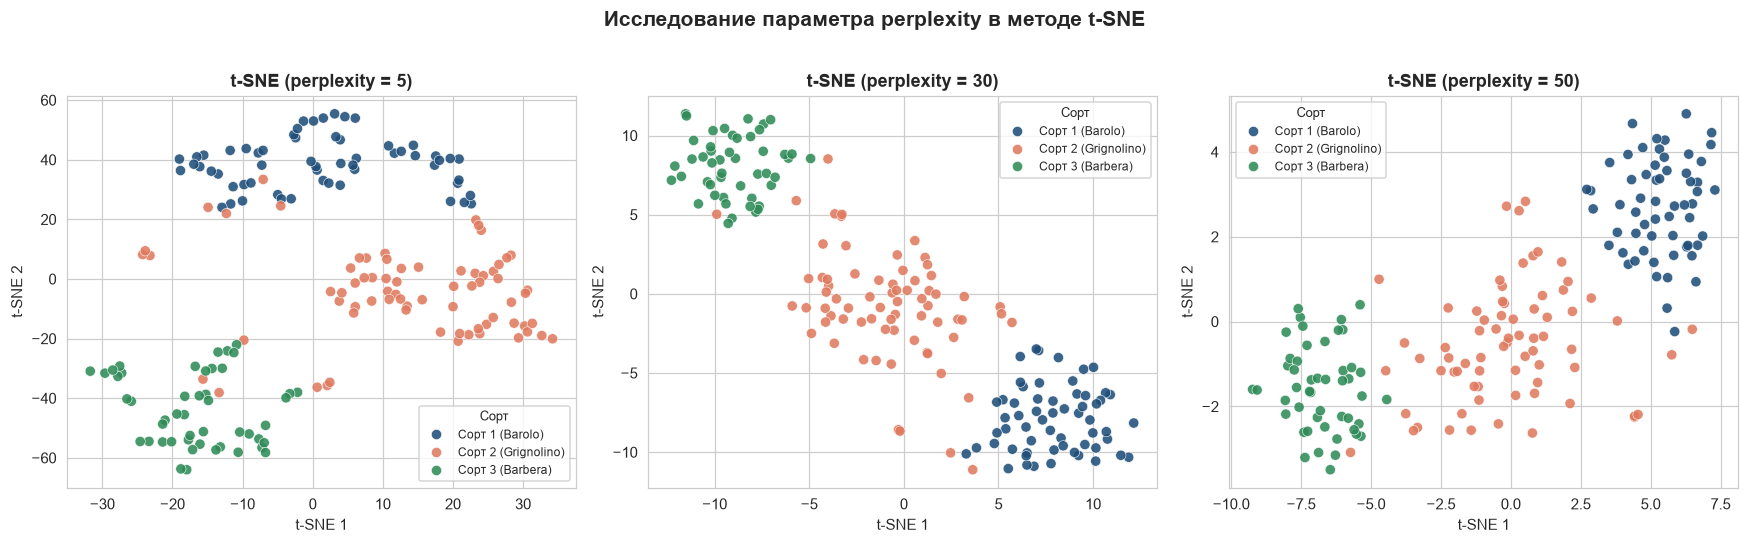

In [9]:
# 5.1 Исследование параметра perplexity для t-SNE
perplexities = [5, 30, 50]
tsne_embeddings = {}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, perp in zip(axes, perplexities):
    tsne = TSNE(n_components=2, perplexity=perp, random_state=RANDOM_STATE, init='pca', learning_rate='auto')
    Z_tsne = tsne.fit_transform(X_scaled)
    tsne_embeddings[perp] = Z_tsne
    sns.scatterplot(x=Z_tsne[:, 0], y=Z_tsne[:, 1], hue=y_names, hue_order=HUE_ORDER,
                    palette=PALETTE, s=45, alpha=0.88, edgecolor='white', linewidth=0.4, ax=ax)
    ax.set_title(f"t-SNE (perplexity = {perp})", fontsize=11.5, fontweight='bold')
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")
    ax.legend(title="Сорт", fontsize=8, title_fontsize=8.5)

plt.suptitle("Исследование параметра perplexity в методе t-SNE", fontsize=13.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

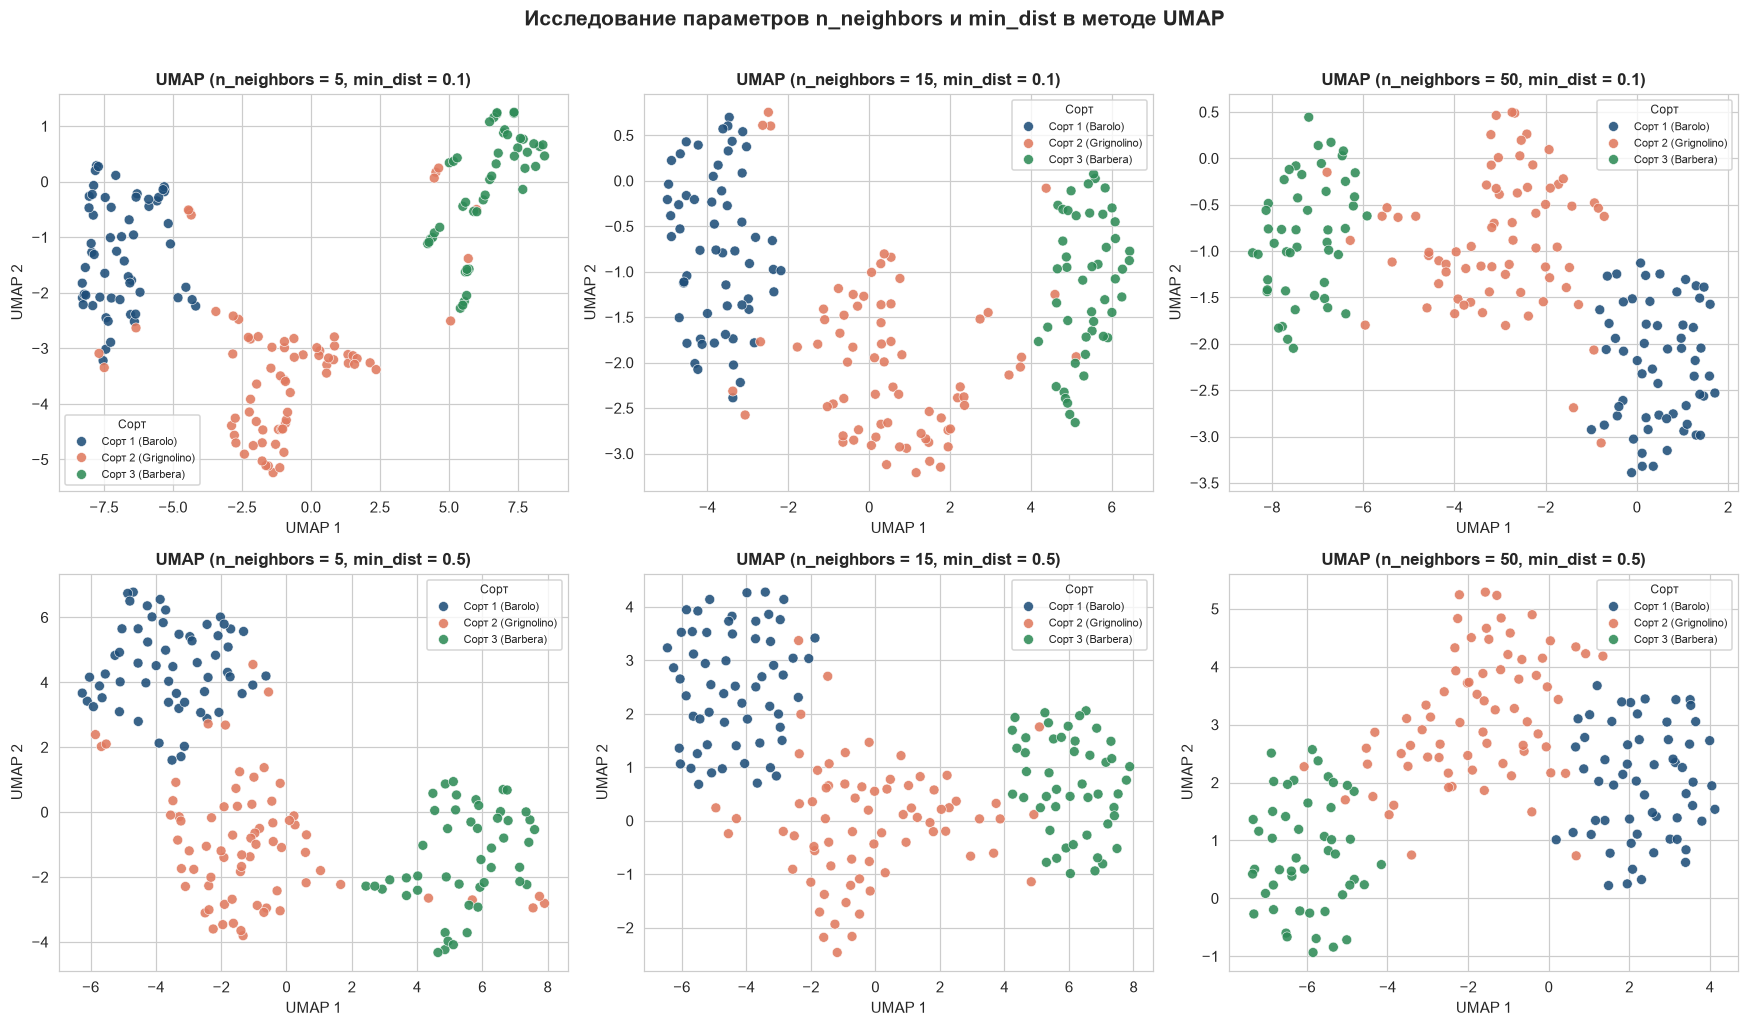

In [10]:
# Вспомогательная чистая реализация UMAP (используется автоматически, если не установлен umap-learn)
class SimpleUMAP:
    def __init__(self, n_components=2, n_neighbors=15, min_dist=0.1, n_epochs=300, learning_rate=1.0, random_state=42):
        self.n_components = n_components
        self.n_neighbors = n_neighbors
        self.min_dist = min_dist
        self.n_epochs = n_epochs
        self.learning_rate = learning_rate
        self.random_state = random_state

    @staticmethod
    def _find_ab_params(spread, min_dist):
        def curve(x, a, b):
            return 1.0 / (1.0 + a * x ** (2 * b))
        xv = np.linspace(0, spread * 3, 300)
        yv = np.where(xv < min_dist, 1.0, np.exp(-(xv - min_dist) / spread))
        params, _ = scipy.optimize.curve_fit(curve, xv, yv, p0=[1.0, 1.0], maxfev=5000)
        return float(params[0]), float(params[1])

    def fit_transform(self, X):
        rng = np.random.RandomState(self.random_state)
        n = X.shape[0]
        k = min(self.n_neighbors, n - 1)
        D = cdist(X, X, metric='euclidean')
        P = np.zeros((n, n), dtype=float)
        target = np.log2(k)
        for i in range(n):
            idx = np.argsort(D[i])[1:k+1]
            dists = D[i, idx]
            rho = dists[0]
            lo, hi = 1e-5, 1e3
            for _ in range(64):
                mid = (lo + hi) / 2.0
                if np.sum(np.exp(-np.maximum(0.0, dists - rho) / mid)) > target:
                    hi = mid
                else:
                    lo = mid
            P[i, idx] = np.exp(-np.maximum(0.0, dists - rho) / ((lo + hi) / 2.0))

        W = P + P.T - P * P.T
        np.fill_diagonal(W, 0.0)
        L = laplacian(W, normed=True)
        _, evecs = np.linalg.eigh(L)
        emb = evecs[:, 1:self.n_components+1].copy()
        emb = emb / (np.max(np.abs(emb)) + 1e-8) * 10.0 + rng.normal(scale=0.05, size=(n, self.n_components))

        a, b = self._find_ab_params(1.0, self.min_dist)
        rows, cols = np.where(W > 1e-3)
        probs = W[rows, cols] / np.max(W[rows, cols])
        n_neg = 5
        for epoch in range(self.n_epochs):
            alpha = self.learning_rate * (1.0 - epoch / float(self.n_epochs))
            mask = rng.rand(len(rows)) < probs
            ei, ej = rows[mask], cols[mask]
            if len(ei) == 0:
                continue
            diff = emb[ei] - emb[ej]
            dist_sq = np.sum(diff * diff, axis=1) + 1e-8
            grad = np.clip(((-2.0 * a * b * (dist_sq ** (b - 1.0))) / (1.0 + a * (dist_sq ** b)))[:, None] * diff, -4.0, 4.0)
            np.add.at(emb, ei, alpha * grad)
            np.add.at(emb, ej, -alpha * grad)

            ei_rep = np.repeat(ei, n_neg)
            nj = rng.randint(0, n, size=len(ei_rep))
            valid = nj != ei_rep
            ei_rep, nj = ei_rep[valid], nj[valid]
            diff_n = emb[ei_rep] - emb[nj]
            dist_sq_n = np.sum(diff_n * diff_n, axis=1) + 1e-8
            grad_n = np.clip(((2.0 * b) / ((0.001 + dist_sq_n) * (1.0 + a * (dist_sq_n ** b))))[:, None] * diff_n, -4.0, 4.0)
            np.add.at(emb, ei_rep, alpha * grad_n)
        return emb

def run_umap(X, n_neighbors, min_dist):
    if HAS_UMAP:
        return umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, random_state=RANDOM_STATE).fit_transform(X)
    return SimpleUMAP(n_neighbors=n_neighbors, min_dist=min_dist, random_state=RANDOM_STATE).fit_transform(X)

# 5.2 Исследование параметров n_neighbors и min_dist для UMAP
umap_neighbors = [5, 15, 50]
umap_min_dists = [0.1, 0.5]
umap_embeddings = {}

fig, axes = plt.subplots(2, 3, figsize=(16, 9.2))
for r, md in enumerate(umap_min_dists):
    for c, nn in enumerate(umap_neighbors):
        Z_u = run_umap(X_scaled, n_neighbors=nn, min_dist=md)
        umap_embeddings[(nn, md)] = Z_u
        ax = axes[r, c]
        sns.scatterplot(x=Z_u[:, 0], y=Z_u[:, 1], hue=y_names, hue_order=HUE_ORDER,
                        palette=PALETTE, s=42, alpha=0.88, edgecolor='white', linewidth=0.4, ax=ax)
        ax.set_title(f"UMAP (n_neighbors = {nn}, min_dist = {md})", fontsize=11, fontweight='bold')
        ax.set_xlabel("UMAP 1")
        ax.set_ylabel("UMAP 2")
        ax.legend(title="Сорт", fontsize=7.5, title_fontsize=8)

plt.suptitle("Исследование параметров n_neighbors и min_dist в методе UMAP", fontsize=13.5, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

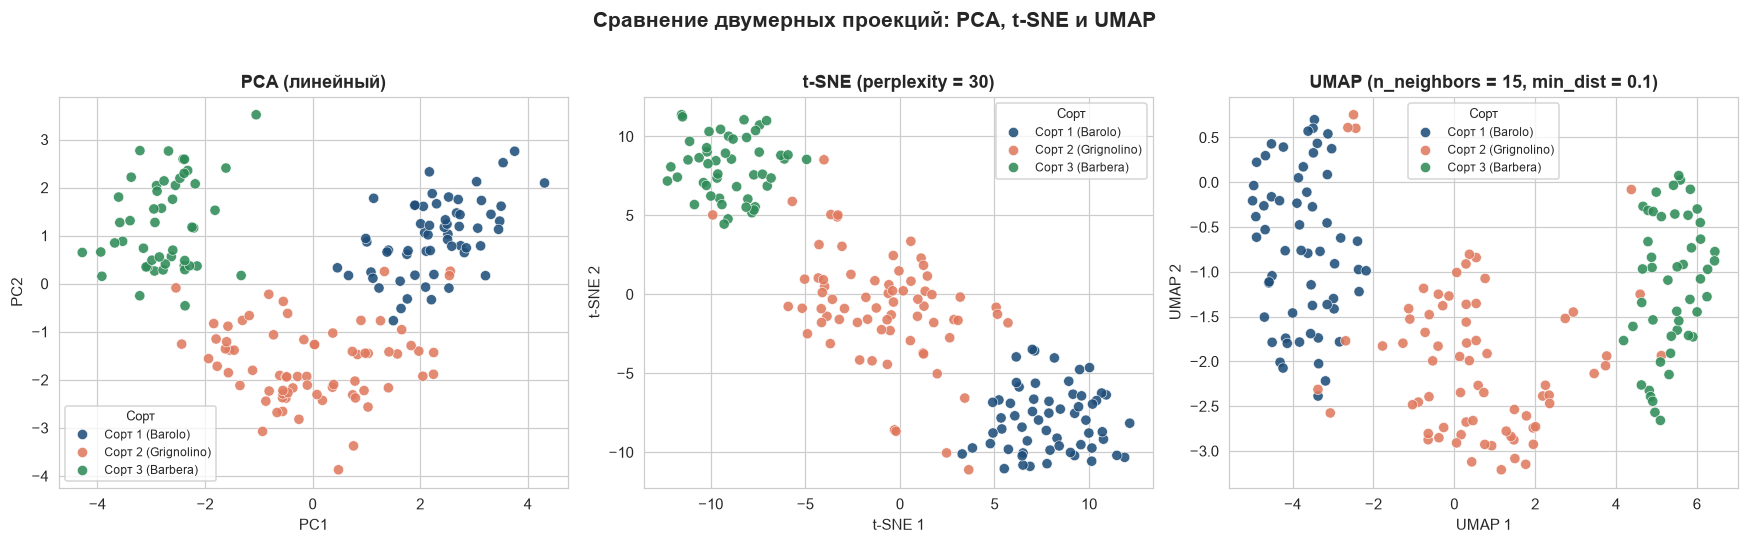

In [11]:
# Сводное сравнение 2D-проекций: PCA vs t-SNE vs UMAP
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
methods_vis = [
    ("PCA (линейный)", Z_full[:, :2], "PC1", "PC2"),
    ("t-SNE (perplexity = 30)", tsne_embeddings[30], "t-SNE 1", "t-SNE 2"),
    ("UMAP (n_neighbors = 15, min_dist = 0.1)", umap_embeddings[(15, 0.1)], "UMAP 1", "UMAP 2"),
]
for ax, (title, coords, xl, yl) in zip(axes, methods_vis):
    sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=y_names, hue_order=HUE_ORDER,
                    palette=PALETTE, s=45, alpha=0.88, edgecolor='white', linewidth=0.4, ax=ax)
    ax.set_title(title, fontsize=11.5, fontweight='bold')
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
    ax.legend(title="Сорт", fontsize=8, title_fontsize=8.5)

plt.suptitle("Сравнение двумерных проекций: PCA, t-SNE и UMAP", fontsize=13.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Ответы на вопросы Задания 5

1. **Как меняется структура данных при разных параметрах?**
   * **t-SNE (`perplexity`):**
     * При `perplexity = 5` алгоритм фокусируется только на ближайших 5 соседях, поэтому кластеры дробятся на вытянутые цепочки и локальные микрогруппы, а отдельные точки выбрасываются на периферию.
     * При `perplexity = 30` формируются три чётких, компактных, хорошо разделённых кластера сортов вин — оптимальный баланс для выборки из 178 объектов.
     * При `perplexity = 50` учитывается почти треть датасета в качестве окружения каждой точки, структура становится более гладкой и глобальной, границы между сортами сближаются.
   * **UMAP (`n_neighbors` и `min_dist`):**
     * Увеличение `n_neighbors` (с 5 до 15 и 50) смещает акцент с тонкой локальной структуры (плотные вытянутые микрокластеры) на сохранение глобальной топологии всего датасета.
     * Увеличение `min_dist` (с 0.1 до 0.5) ослабляет плотность упаковки точек внутри кластеров: при `min_dist = 0.1` группы очень компактны и разделены широкими зазорами, а при `min_dist = 0.5` точки распределяются равномернее по плоскости.
2. **Какой метод даёт наиболее интерпретируемую визуализацию?**
   * По **физическому смыслу осей** безоговорочно лидирует **PCA** — каждая ось задаётся точной линейной формулой через химические показатели вина.
   * По **визуальному разделению кластеров и сохранению топологии** лучше всего проявляют себя **UMAP** (сохраняет и локальные кластеры, и взаимное глобальное расположение: `Сорт 2` строго между `Сортом 1` и `Сортом 3`) и **t-SNE** (`perplexity = 30`).
3. **Почему результаты разных методов могут существенно отличаться?**
   * Методы решают принципиально разные оптимизационные задачи: **PCA** максимизирует глобальную линейную дисперсию; **t-SNE** минимизирует дивергенцию Кульбака–Лейблера между распределениями вероятностей соседства (сохраняя локальные окрестности, но искажая расстояния между далёкими кластерами); **UMAP** строит нечёткий топологический граф на многообразии и оптимизирует кросс-энтропию, удерживая баланс между локальной плотностью и глобальной геометрией.

## Задание 6. Исследование степени сжатия данных (MSE)

Исследуем, как уменьшение числа главных компонент $k$ влияет на точность обратного восстановления исходных стандартизированных данных.  
Поскольку в датасете Wine **13 числовых признаков** ($13 < 15$), в соответствии с условием задания рассматриваем значения:
$$k \in \{2,\; 5,\; 10,\; 13\text{ (максимум)}\}$$
а для визуального анализа строим полную кривую ошибки восстановления $\text{MSE}(k)$ для всех $k = 1 \dots 13$.

=== ТАБЛИЦА ОШИБКИ ВОССТАНОВЛЕНИЯ (MSE) ===


,Число компонент (k),Ошибка восстановления (MSE),Накопленная дисперсия (%)
0,2,0.445937,55.41
1,5,0.198377,80.16
2,10,0.038303,96.17
3,13,0.000000,100.00


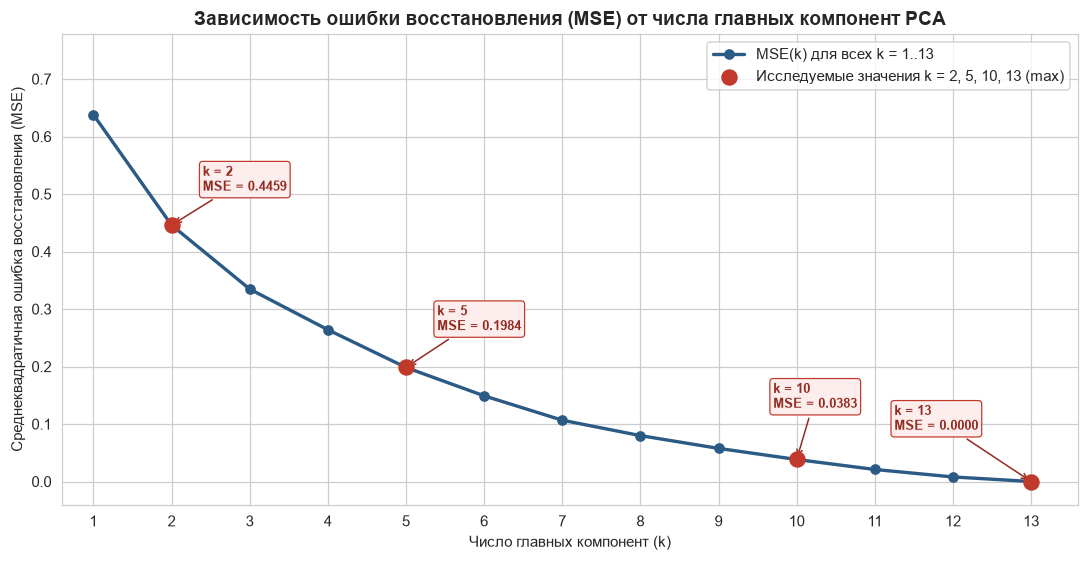

In [12]:
# 6.1–6.3 Снижение размерности, обратное восстановление и расчёт MSE
k_selected = [2, 5, 10, 13]  # 13 — максимально возможное число компонент (d = 13 < 15)
results_selected = []

for k in k_selected:
    pca_k = PCA(n_components=k)
    Z_k = pca_k.fit_transform(X_scaled)
    X_rec = pca_k.inverse_transform(Z_k)
    mse_k = mean_squared_error(X_scaled, X_rec)
    var_k = np.sum(pca_k.explained_variance_ratio_) * 100
    results_selected.append({
        "Число компонент (k)": k,
        "Ошибка восстановления (MSE)": round(mse_k, 6),
        "Накопленная дисперсия (%)": round(var_k, 2)
    })

mse_table = pd.DataFrame(results_selected)
print("=== ТАБЛИЦА ОШИБКИ ВОССТАНОВЛЕНИЯ (MSE) ===")
display(mse_table)

# 6.4 График зависимости MSE от числа компонент (полный диапазон k = 1..13)
all_ks = list(range(1, len(features) + 1))
all_mses = []
for k in all_ks:
    pca_k = PCA(n_components=k)
    X_rec = pca_k.inverse_transform(pca_k.fit_transform(X_scaled))
    all_mses.append(mean_squared_error(X_scaled, X_rec))

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(all_ks, all_mses, marker='o', color='#2B5B84', linewidth=2.2, markersize=6, label='MSE(k) для всех k = 1..13')
sel_mses = [all_mses[k - 1] for k in k_selected]
ax.scatter(k_selected, sel_mses, color='#C0392B', s=95, zorder=5, label='Исследуемые значения k = 2, 5, 10, 13 (max)')

offsets = {2: (0.4, 0.06), 5: (0.4, 0.065), 10: (-0.3, 0.09), 13: (-1.75, 0.09)}
for k_val, m_val in zip(k_selected, sel_mses):
    dx, dy = offsets[k_val]
    ax.annotate(f"k = {k_val}\nMSE = {m_val:.4f}",
                xy=(k_val, m_val),
                xytext=(k_val + dx, m_val + dy),
                fontsize=8.8, fontweight='bold', color='#922B21',
                bbox=dict(boxstyle="round,pad=0.25", fc="#FDEDEC", ec="#C0392B", lw=0.8),
                arrowprops=dict(arrowstyle='->', color='#922B21', lw=1.0))

ax.set_xticks(all_ks)
ax.set_xlim(0.6, 13.6)
ax.set_ylim(-0.04, max(all_mses) + 0.14)
ax.set_xlabel("Число главных компонент (k)")
ax.set_ylabel("Среднеквадратичная ошибка восстановления (MSE)")
ax.set_title("Зависимость ошибки восстановления (MSE) от числа главных компонент PCA", fontsize=12.5, fontweight='bold')
ax.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

### 6.4–6.5 Анализ графика и ответы на вопросы Задания 6

**Форма графика:** Ошибка MSE убывает монотонно и наиболее стремительно на участке $k = 1 \dots 5$ (с $0.6380$ при $k=1$ до $0.1984$ при $k=5$). После $k = 8$ кривая становится пологой: добавление каждой следующей компоненты уменьшает MSE менее чем на $0.025$ (например, переход $k = 8 \to 9$ снижает ошибку на $0.0222$, а далее шаги ещё меньше).

1. **Почему при малом числе компонент ошибка восстановления большая?**  
   При $k = 2$ мы отбрасываем 11 ортогональных направлений, на которые приходится **44.59%** суммарной дисперсии данных. Проекция сохраняет общую структуру классов, но теряет индивидуальные детали химического состава каждого образца, из-за чего $\text{MSE} = 0.4459$.
2. **Почему увеличение числа компонент уменьшает ошибку?**  
   Каждая добавленная компонента представляет собой новый ортогональный базисный вектор, возвращающий в реконструкцию соответствующую долю дисперсии исходного пространства, поэтому остаточная ошибка строго уменьшается.
3. **Можно ли полностью восстановить исходные данные при использовании всех компонент?**  
   **Да.** При $k = d = 13$ матрица собственных векторов $W$ образует полный ортонормированный базис ($W^T W = I$). Преобразование становится точно обратимым, и ошибка падает до нуля ($\text{MSE} = 0.000000$, с точностью до машинного эпсилон $\sim 10^{-31}$).
4. **Как это связано с объяснённой дисперсией PCA?**  
   Для стандартизированных данных (где дисперсия каждого признака равна $1$, а сумма всех долей дисперсии равна $1$) выполняется точное равенство:
   $$\text{MSE}(k) = 1 - \sum_{i=1}^{k} \text{EVR}_i = \sum_{i=k+1}^{d} \text{EVR}_i$$
   Например, при $k = 5$ накопленная доля дисперсии равна $0.8016$, а ошибка восстановления равна $1 - 0.8016 = 0.1984$.
5. **Как определить разумное число компонент?**  
   На практике используют комбинацию двух критериев:
   * **Метод «локтя»** на графике MSE / собственных значений — точка, после которой скорость падения ошибки резко замедляется (для Wine это зона $k = 5\dots 7$).
   * **Порог накопленной объяснённой дисперсии** (обычно $80\%\text{–}95\%$): для компактного представления без серьёзных потерь достаточно **$k = 5$** (80.16% дисперсии, сжатие в 2.6 раза) или **$k = 7$** (89.34% дисперсии, MSE = 0.1066), а для почти идеального восстановления — **$k = 10$** (96.17% дисперсии, MSE = 0.0383).

## Задание 7. Итоговый анализ и выводы

1. **Какую роль играет снижение размерности в анализе данных?**  
   Снижение размерности решает четыре ключевые задачи: устраняет мультиколлинеарность (избыточность коррелированных признаков, как фенольный блок в датасете Wine), подавляет случайный шум, ускоряет обучение алгоритмов машинного обучения и позволяет наглядно визуализировать многомерные данные на плоскости (2D) или в 3D.

2. **Всегда ли уменьшение размерности полезно?**  
   **Нет.** Сжатие пространства неизбежно сопровождается потерей части информации (что подтверждено ростом MSE при малых $k$) и усложняет прямую интерпретацию новых координат по сравнению с исходными физическими величинами. Если признаков изначально мало, они слабо коррелированы и не содержат шума, снижение размерности может даже ухудшить качество предсказательных моделей.

3. **В каких случаях линейные методы могут работать хуже нелинейных?**  
   Линейный PCA ищет плоские гиперплоскости и плохо справляется с данными, лежащими на искривлённых нелинейных многообразиях (спирали, кольца, вложенные сферы, изображения, текстовые эмбеддинги, сложные биоинформатические профили), где евклидово расстояние «по прямой» не отражает реальную близость объектов. В таких задачах нелинейные методы (t-SNE, UMAP) значительно лучше раскрывают локальные кластеры.

4. **Преимущества и ограничения методов PCA, t-SNE и UMAP:**

| Метод | Преимущества | Ограничения |
| :--- | :--- | :--- |
| **PCA** | Очень быстрый, детерминированный, математически прозрачный; даёт интерпретируемые нагрузки; поддерживает прямое (`transform`) и обратное (`inverse_transform`) преобразование для сжатия и восстановления данных. | Улавливает только линейные зависимости; чувствителен к масштабу признаков (требует стандартизации) и к сильным выбросам. |
| **t-SNE** | Превосходно выявляет и визуально разделяет сложные нелинейные локальные кластеры. | Вычислительно затратен на больших объёмах данных; стохастический; не поддерживает проекцию новых точек (`transform`); искажает глобальные расстояния между кластерами; сильно зависит от `perplexity`. |
| **UMAP** | Значительно быстрее t-SNE; сохраняет баланс между локальной структурой и глобальной топологией; поддерживает проецирование новых объектов (`transform`). | Требует подбора гиперпараметров (`n_neighbors`, `min_dist`); оси проекции не имеют прямой линейной формулы; результат может слегка варьироваться от `random_state`. |